# Метод k-ближайших соседей

## Введение



В этой лекции мы рассмотрим классический алгоритм машинного обучения: **Метод k-ближайших соседей (k-Nearest Neighbors, kNN)** — «ленивый» алгоритм, который не строит явную модель, а делает предсказание на основе схожести с обучающими примерами.

> **Задачи, которые мы разберём:**
> - Классификация цветков ириса по размерам лепестков и чашелистиков (**Iris**);
> - Регрессия: предсказание длины лепестка по размерам чашелистика;


---
# Часть 1. Метод k-ближайших соседей
---



## 1.1. Интуиция

**Метод k-ближайших соседей (k Nearest Neighbors, или kNN)** — популярный алгоритм классификации, который используется в разных типах задач машинного обучения. Наравне с деревом решений это один из самых понятных подходов к классификации.

На интуитивном уровне суть метода проста:

> **«Посмотри на соседей вокруг: какие из них преобладают — таков и ты».**

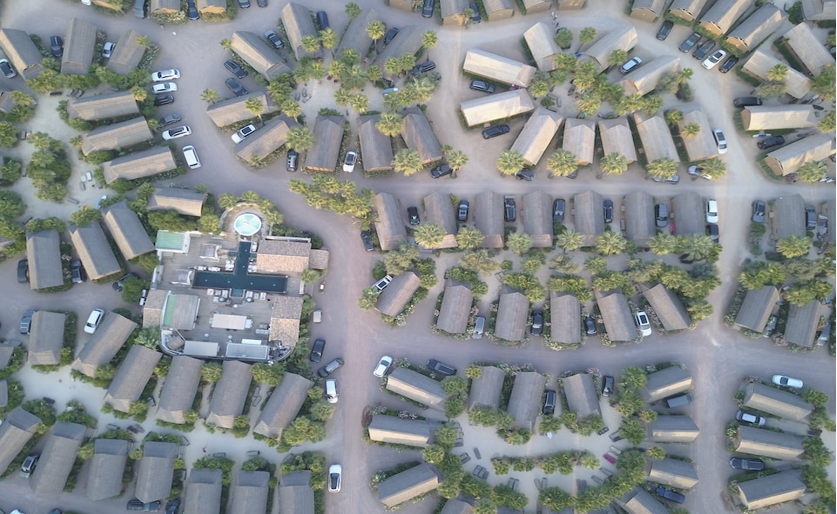

Формально основой метода является **[гипотеза компактности](http://www.machinelearning.ru/wiki/index.php?title=%D0%93%D0%B8%D0%BF%D0%BE%D1%82%D0%B5%D0%B7%D0%B0_%D0%BA%D0%BE%D0%BC%D0%BF%D0%B0%D0%BA%D1%82%D0%BD%D0%BE%D1%81%D1%82%D0%B8)**: если метрика расстояния между примерами введена удачно, то схожие примеры гораздо чаще лежат в одном классе, чем в разных.



>  **Биологический пример.** Представьте, что вы нашли новый цветок и хотите понять его вид. Если измерить длину и ширину лепестка, а затем посмотреть на уже известные цветы с похожими размерами — большинство из них, скорее всего, окажутся того же вида. Именно так и работает kNN.

## 1.2. Классификация и регрессия



- **Классификация.** Объект присваивается тому классу, который является **наиболее распространённым** среди *k* соседей данного элемента, классы которых уже известны.
- **Регрессия.** Объекту присваивается **среднее значение** по *k* ближайшим к нему объектам, значения которых уже известны.



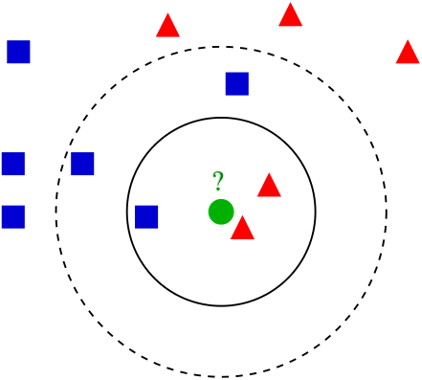

**Пример классификации:**
Есть тестовый образец (зелёный круг). Синие квадраты — класс 1, красные треугольники — класс 2.

- Если рассматриваемая область — **малый круг** (*k=2*), то объект классифицируется как **класс 2** (внутри 2 треугольника и 1 квадрат).
- Если рассматриваемая область — **большой круг** (*k=3*), то объект классифицируется как **класс 1** (внутри 3 квадрата против 2 треугольников).

Этот пример наглядно показывает, что выбор *k* критически влияет на результат.

## 1.3. Метрики расстояния



Выбор метрики расстояния — ключевой момент в kNN. Наиболее популярные метрики:

**Евклидово расстояние:**

$$d_{\text{евклидово}} = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}$$

**Манхэттенское расстояние (расстояние городских кварталов):**

$$d_{\text{манхэттенское}} = \sum_{i=1}^{n} |x_i - y_i|$$

**Расстояние Минковского (обобщение двух предыдущих):**

$$d_{\text{Минковского}} = \left(\sum_{i=1}^{n} |x_i - y_i|^p\right)^{1/p}$$

При $p = 2$ метрика Минковского совпадает с евклидовой, при $p = 1$ — с манхэттенской.

>  В некоторых задачах евклидово расстояние учитывает «совместное» отклонение признаков (например, длину и ширину лепестка), а манхэттенское — сумму независимых отклонений. Для признаков разной природы (например, размеров и формы) выбор метрики может существенно повлиять на результат.

## 1.4. Нормализация признаков



Разные атрибуты обычно обладают разным диапазоном значений. Например, атрибут **A** — в диапазоне от 0.01 до 0.05, а атрибут **Б** — от 500 до 1000. В таком случае значения дистанции будут сильно зависеть от атрибутов с большими диапазонами.

Поэтому данные в большинстве случаев проходят через **нормализацию**. Есть два основных способа:

### MinMax-нормализация

$$x' = \frac{x - \min[X]}{\max[X] - \min[X]}$$

Все значения будут в диапазоне от 0 до 1.

### Z-нормализация (стандартизация)

$$x' = \frac{x - M[X]}{\sigma[X]}$$

где $M[X]$ — среднее, $\sigma[X]$ — среднеквадратичное отклонение. После преобразования признак имеет среднее 0 и стандартное отклонение 1.

>  **Важно.** В kNN нормализация **обязательна**, если признаки измерены в разных шкалах. Иначе один признак с большим разбросом полностью «задавит» остальные.

## 1.5. Алгоритм работы



1. **Задать k.**
2. Для каждого образца в данных:
   - вычислить расстояние между примером запроса и текущим примером из данных;
   - добавить индекс образца в упорядоченную коллекцию вместе с его расстоянием.
3. Отсортировать коллекцию расстояний и индексов по возрастанию расстояния.
4. Выбрать первые *k* записей из отсортированной коллекции.
   - **Регрессия:** вернуть среднее значение выбранных *k* меток.
   - **Классификация:** вернуть наиболее часто встречающееся значение выбранных *k* меток.

## 1.6. Выбор k



Не существует конкретного способа определить наилучшее значение для *k*, поэтому нужно пробовать несколько значений, чтобы найти лучшее.

Чаще всего наиболее предпочтительным значением является **k = 5**.

**Проблемы крайних значений:**

1. **Низкое k (1 или 2):** приводит к эффекту **недообучения** — модель тогда слишком чувствительна к шуму и выбросам.
2. **Высокое k:** на первый взгляд выглядит приемлемо, однако возможны трудности с производительностью модели, а также повышается риск **переобучения** (модель «усредняет» слишком много и теряет локальную структуру).

**Практическое правило:** $k \approx \sqrt{n}$, где $n$ — размер обучающей выборки. Также удобно брать нечётное *k* в задаче бинарной классификации (чтобы избежать ничьих).

## 1.7. Преимущества и недостатки



###  Преимущества

- Алгоритм прост и легко реализуем.
- Не чувствителен при *k>2* к выбросам (в отличие от линейных моделей).
- Нет необходимости строить модель, настраивать несколько параметров или делать дополнительные допущения.
- Универсален: подходит и для классификации, и для регрессии.

###  Недостатки

- Алгоритм работает значительно медленнее при увеличении объёма выборки, числа предикторов или независимых переменных.
- Отсюда — большие вычислительные затраты во время выполнения алгоритма (все расстояния пересчитываются заново для каждого прогноза).
- Всегда нужно определять оптимальное значение *k*.
- Требует хранения всей обучающей выборки.
- Чувствителен к масштабу признаков -> обязательна нормализация.

---
## 1.8. Практика: kNN (датасет Iris)
---

**Датасет Iris** — классический биологический набор данных, собранный Рональдом Фишером в 1936 году. Он содержит измерения 150 цветков ириса трёх видов:

- **Iris-setosa** (щетинистый)
- **Iris-versicolor** (разноцветный)
- **Iris-virginica** (виргинский)

Для каждого цветка измерены 4 признака: длина и ширина чашелистика (sepal), длина и ширина лепестка (petal).

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data
y = iris.target

df = pd.DataFrame(X, columns=iris.feature_names)
df["species"] = [iris.target_names[i] for i in y]

print("Размер датасета:", df.shape)
df.head(10)

Размер датасета: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa
8,4.4,2.9,1.4,0.2,setosa
9,4.9,3.1,1.5,0.1,setosa


In [3]:
print("Распределение классов:")
print(df["species"].value_counts())

df.describe()

Распределение классов:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


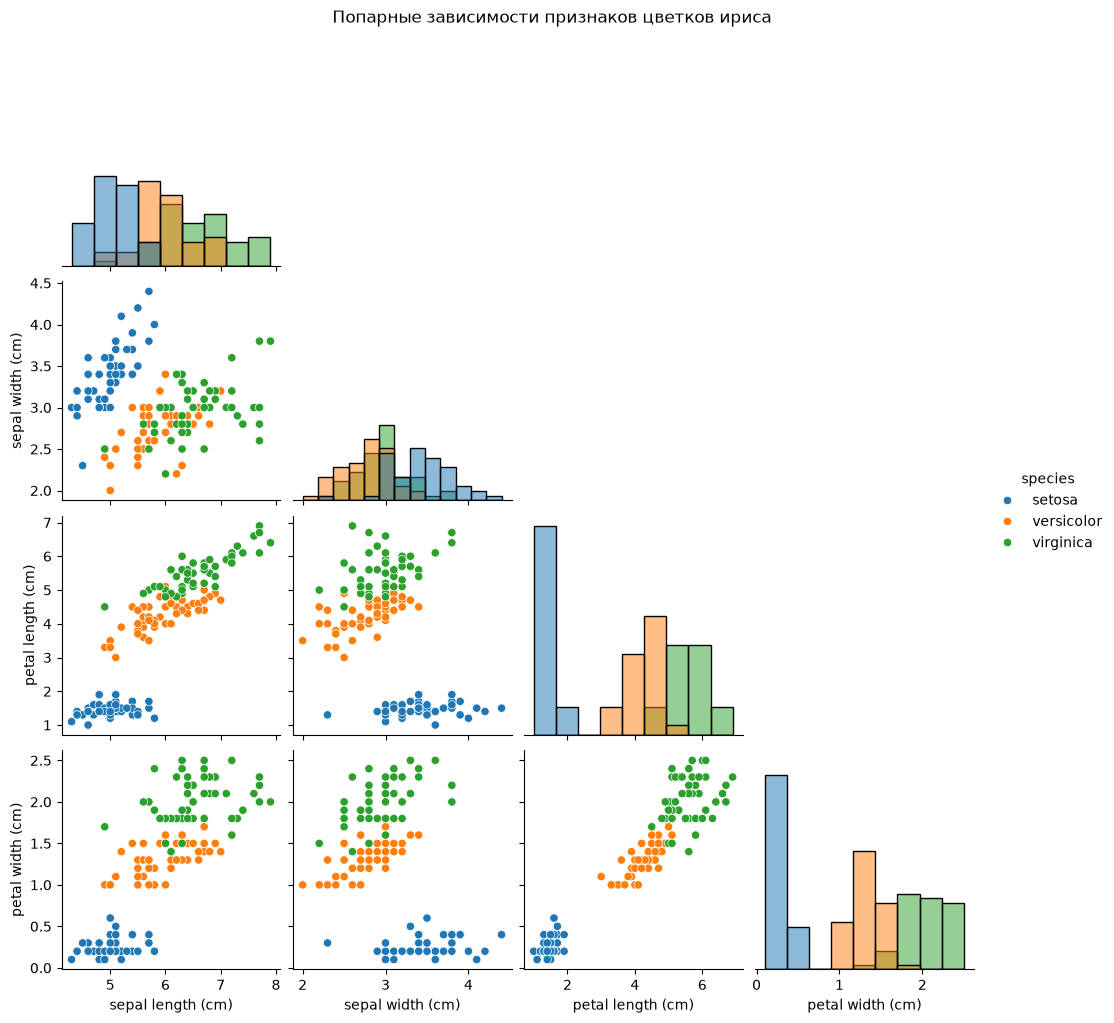

In [4]:
sns.pairplot(df, hue="species", diag_kind="hist", corner=True)
plt.suptitle("Попарные зависимости признаков цветков ириса", y=1.02)
plt.show()

### Разделение на обучающую и тестовую выборки

Используем **стратифицированное** разбиение, чтобы сохранить пропорции классов, и **Z-нормализацию** — kNN чувствителен к масштабу признаков.

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Обучающая выборка:", X_train_scaled.shape)
print("Тестовая выборка:", X_test_scaled.shape)

Обучающая выборка: (105, 4)
Тестовая выборка: (45, 4)


### Обучение классификатора kNN

In [6]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print()
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy: 0.9111

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.79      1.00      0.88        15
   virginica       1.00      0.73      0.85        15

    accuracy                           0.91        45
   macro avg       0.93      0.91      0.91        45
weighted avg       0.93      0.91      0.91        45



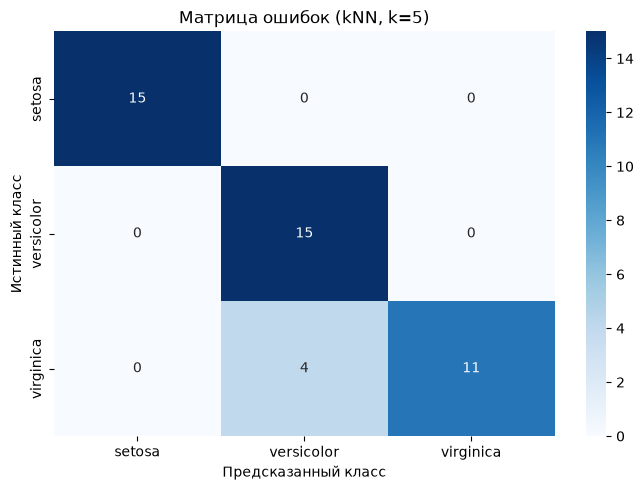

In [7]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names,
)
plt.title("Матрица ошибок (kNN, k=5)")
plt.ylabel("Истинный класс")
plt.xlabel("Предсказанный класс")
plt.tight_layout()
plt.show()

### Подбор оптимального k



Проверим качество модели при разных значениях *k*.

In [8]:
from sklearn.model_selection import cross_val_score

k_range = range(1, 26)
cv_scores = []

for k in k_range:
    model = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(model, X_train_scaled, y_train, cv=5, scoring="accuracy")
    cv_scores.append(scores.mean())

best_k = k_range[int(np.argmax(cv_scores))]
print("Лучшее k по кросс-валидации:", best_k)
print("Accuracy:", round(max(cv_scores), 4))

Лучшее k по кросс-валидации: 14
Accuracy: 0.9714


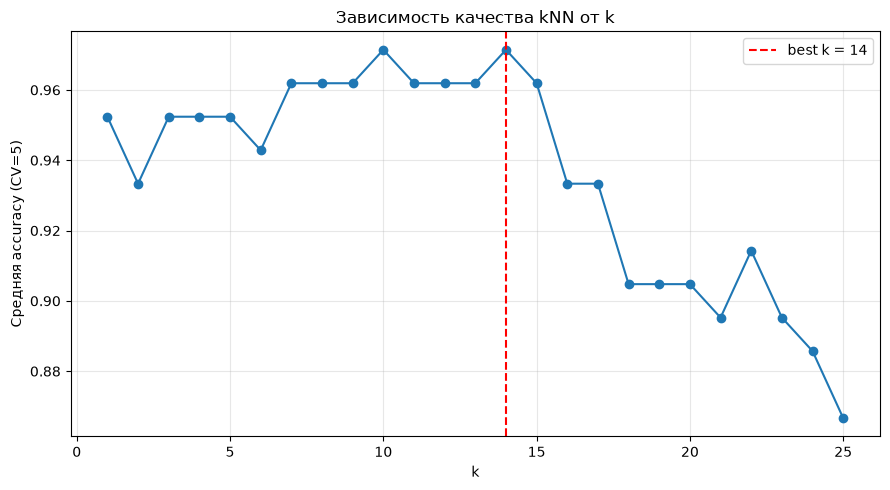

In [9]:
plt.figure(figsize=(9, 5))
plt.plot(k_range, cv_scores, marker="o")
plt.axvline(best_k, color="red", linestyle="--", label=f"best k = {best_k}")
plt.xlabel("k")
plt.ylabel("Средняя accuracy (CV=5)")
plt.title("Зависимость качества kNN от k")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Визуализация границ решения (plotly)

Чтобы увидеть, как kNN делит признаковое пространство, оставим только два признака — длину и ширину лепестка.

In [10]:
import plotly.graph_objects as go

# Возьмём два признака: petal length (индекс 2) и petal width (индекс 3)
X_vis = X[:, [2, 3]]
X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(
    X_vis, y, test_size=0.3, random_state=42, stratify=y
)

clf_v = KNeighborsClassifier(n_neighbors=5)
clf_v.fit(X_train_v, y_train_v)

mesh_size = 0.05
margin = 0.5
x_min, x_max = X_vis[:, 0].min() - margin, X_vis[:, 0].max() + margin
y_min, y_max = X_vis[:, 1].min() - margin, X_vis[:, 1].max() + margin
xrange = np.arange(x_min, x_max, mesh_size)
yrange = np.arange(y_min, y_max, mesh_size)
xx, yy = np.meshgrid(xrange, yrange)

Z = clf_v.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

fig = go.Figure()
fig.add_trace(
    go.Contour(
        x=xrange,
        y=yrange,
        z=Z,
        colorscale="Viridis",
        opacity=0.5,
        showscale=False,
        hoverinfo="skip",
    )
)

markers = ["circle", "square", "diamond"]
for cls in np.unique(y):
    mask_train = y_train_v == cls
    mask_test = y_test_v == cls
    fig.add_trace(
        go.Scatter(
            x=X_train_v[mask_train, 0],
            y=X_train_v[mask_train, 1],
            mode="markers",
            marker={
                "symbol": markers[cls],
                "size": 10,
                "line": {"width": 1, "color": "black"},
            },
            name=f"{iris.target_names[cls]} (train)",
        )
    )
    fig.add_trace(
        go.Scatter(
            x=X_test_v[mask_test, 0],
            y=X_test_v[mask_test, 1],
            mode="markers",
            marker={
                "symbol": markers[cls],
                "size": 14,
                "line": {"width": 2, "color": "red"},
            },
            name=f"{iris.target_names[cls]} (test)",
        )
    )

fig.update_layout(
    title="Границы решения kNN (k=5) на датасете Iris",
    xaxis_title="Длина лепестка, см",
    yaxis_title="Ширина лепестка, см",
    height=600,
)
fig.show()

---
## 1.9. Практика: kNN как регрессор
---



Теперь используем kNN для регрессии. Задача: **по размерам чашелистика (sepal length, sepal width) предсказать длину лепестка (petal length)**.

Это типичная задача морфометрии: по легко измеримым внешним параметрам оценить внутренние.

In [11]:
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor

X_reg = X[:, [0, 1]]  # sepal length, sepal width
y_reg = X[:, 2]  # petal length

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.3, random_state=42
)

scaler_r = StandardScaler()
X_train_r = scaler_r.fit_transform(X_train_r)
X_test_r = scaler_r.transform(X_test_r)

knnr = KNeighborsRegressor(n_neighbors=5)
knnr.fit(X_train_r, y_train_r)
y_pred_r = knnr.predict(X_test_r)

rmse = np.sqrt(mean_squared_error(y_test_r, y_pred_r))
r2 = r2_score(y_test_r, y_pred_r)

print(f"RMSE: {rmse:.4f} см")
print(f"R²:   {r2:.4f}")

RMSE: 0.4676 см
R²:   0.9352


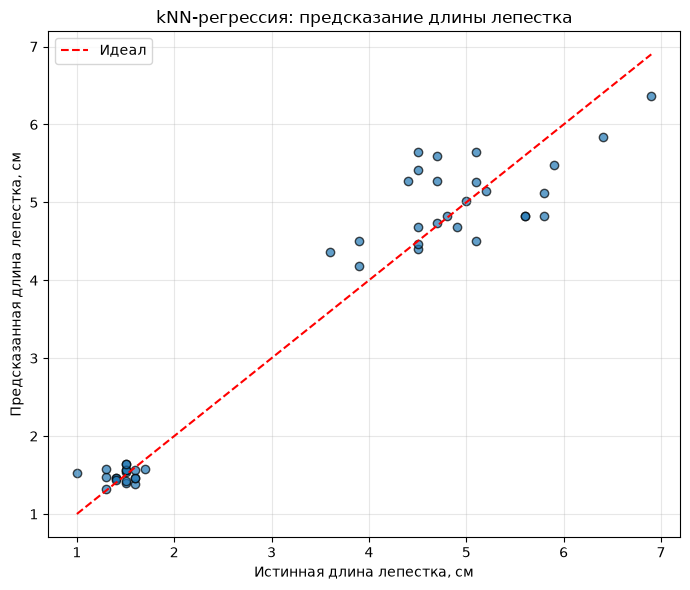

In [12]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test_r, y_pred_r, alpha=0.7, edgecolor="k")
plt.plot(
    [y_test_r.min(), y_test_r.max()],
    [y_test_r.min(), y_test_r.max()],
    "r--",
    label="Идеал",
)
plt.xlabel("Истинная длина лепестка, см")
plt.ylabel("Предсказанная длина лепестка, см")
plt.title("kNN-регрессия: предсказание длины лепестка")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

>  **Вывод по kNN.**
> Метод даёт отличные результаты на биологических данных с хорошо разделимыми классами (Iris — accuracy ≈ 0.9–1.0). В регрессии kNN показывает умеренное качество, поскольку усредняет значения соседей — модель «сглаживает» зависимость.
>
> **Ключевые моменты для практики:**
> - Обязательно нормализуйте признаки;
> - Подбирайте *k* через кросс-валидацию;
